### Setup

In [1]:
import copy
import numpy as np
import matplotlib.pyplot as plt
import torch
import torch.nn as nn
import torch.nn.functional as F
import torchvision
from torch.utils.data import DataLoader, TensorDataset

torch.manual_seed(42)
np.random.seed(42)

### Task 1: Load MNIST and Train the Baseline CNN, Report Clean Accuracy

In [2]:
def load_mnist(train):
    ds = torchvision.datasets.MNIST("/content/data", train=train, download=True)
    return ds.data.float().div(255).unsqueeze(1), ds.targets

x_train, y_train = load_mnist(True)
x_test, y_test = load_mnist(False)
train_loader = DataLoader(TensorDataset(x_train, y_train), batch_size=64, shuffle=True)

class DigitCNN(nn.Module):
    def __init__(self):
        super().__init__()
        self.conv1 = nn.Conv2d(1, 16, 5)
        self.conv2 = nn.Conv2d(16, 32, 5)
        self.fc1 = nn.Linear(512, 128)
        self.fc2 = nn.Linear(128, 10)

    def forward(self, x):
        x = F.max_pool2d(F.relu(self.conv1(x)), 2)
        x = F.max_pool2d(F.relu(self.conv2(x)), 2)
        x = F.relu(self.fc1(x.flatten(1)))
        return self.fc2(x)

def accuracy(model, attack=None, eps=0.0, bs=1000):
    model.eval()
    correct = 0
    for i in range(0, len(x_test), bs):
        x, y = x_test[i:i + bs], y_test[i:i + bs]
        if attack is not None:
            x = attack(model, x, y, eps)
        with torch.no_grad():
            correct += (model(x).argmax(1) == y).sum().item()
    return correct / len(x_test) * 100

model = DigitCNN()
opt = torch.optim.Adam(model.parameters(), lr=0.001)

print("Training baseline CNN (2 epochs)...", end=" ")
for epoch in range(2):
    model.train()
    for x, y in train_loader:
        opt.zero_grad()
        F.cross_entropy(model(x), y).backward()
        opt.step()
print("done.")

clean_acc = accuracy(model)
print(f"Clean test accuracy : {clean_acc:.1f} %")

100%|██████████| 9.91M/9.91M [00:00<00:00, 12.5MB/s]
100%|██████████| 28.9k/28.9k [00:00<00:00, 345kB/s]
100%|██████████| 1.65M/1.65M [00:00<00:00, 3.18MB/s]
100%|██████████| 4.54k/4.54k [00:00<00:00, 14.4MB/s]


Training baseline CNN (2 epochs)... done.
Clean test accuracy : 98.9 %


### Task 2: FGSM Attack on the Baseline Model

In [3]:
EPS_LIST = [0.0, 0.05, 0.10, 0.20, 0.30]

def fgsm(model, x, y, eps):
    if eps == 0:
        return x
    x = x.clone().requires_grad_(True)
    grad, = torch.autograd.grad(F.cross_entropy(model(x), y), x)
    return (x + eps * grad.sign()).clamp(0, 1).detach()

fgsm_accs = [accuracy(model, fgsm, e) for e in EPS_LIST]

print("EPSILON FGSM_ACC")
print("-" * 20)
for e, f in zip(EPS_LIST, fgsm_accs):
    print(f"{e:.2f} {f:.1f} %")

EPSILON FGSM_ACC
--------------------
0.00 98.9 %
0.05 94.8 %
0.10 81.4 %
0.20 31.3 %
0.30 4.6 %


### Task 3: PGD Attack and Comparison with FGSM

In [4]:
def pgd(model, x, y, eps, steps=10):
    if eps == 0:
        return x
    alpha = eps / 4
    x_adv = (x + torch.empty_like(x).uniform_(-eps, eps)).clamp(0, 1)
    for _ in range(steps):
        x_adv.requires_grad_(True)
        grad, = torch.autograd.grad(F.cross_entropy(model(x_adv), y), x_adv)
        x_adv = x_adv.detach() + alpha * grad.sign()
        x_adv = torch.min(torch.max(x_adv, x - eps), x + eps).clamp(0, 1)
    return x_adv.detach()

pgd_accs = [accuracy(model, pgd, e) for e in EPS_LIST]

print("EPSILON FGSM_ACC PGD_ACC")
print("-" * 31)
for e, f, p in zip(EPS_LIST, fgsm_accs, pgd_accs):
    print(f"{e:.2f} {f:.1f} % {p:.1f} %")
print("-" * 31)

EPSILON FGSM_ACC PGD_ACC
-------------------------------
0.00 98.9 % 98.9 %
0.05 94.8 % 93.9 %
0.10 81.4 % 71.2 %
0.20 31.3 % 7.0 %
0.30 4.6 % 0.0 %
-------------------------------


### Task 4: Clean vs FGSM Adversarial Digits (epsilon = 0.20)

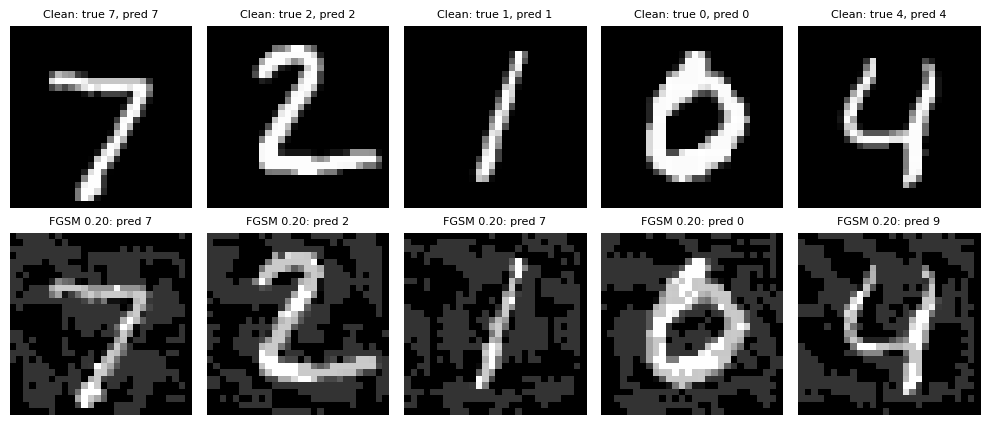

Mis-read digits (true->predicted): ['1->7', '4->9']
Mis-read digits saved : clean_vs_adversarial.png
Attack success (eps=0.20): FGSM 68.7 %, PGD 93.0 %


In [5]:
x5, y5 = x_test[:5], y_test[:5]
x5_adv = fgsm(model, x5, y5, 0.20)
with torch.no_grad():
    pred_clean = model(x5).argmax(1)
    pred_adv = model(x5_adv).argmax(1)

fig, ax = plt.subplots(2, 5, figsize=(10, 4.4))
for i in range(5):
    ax[0, i].imshow(x5[i, 0], cmap="gray"); ax[0, i].set_title(f"Clean: true {y5[i]}, pred {pred_clean[i]}", fontsize=8)
    ax[1, i].imshow(x5_adv[i, 0], cmap="gray"); ax[1, i].set_title(f"FGSM 0.20: pred {pred_adv[i]}", fontsize=8)
    ax[0, i].axis("off"); ax[1, i].axis("off")
plt.tight_layout()
plt.savefig("clean_vs_adversarial.png", dpi=150)
plt.show()

misread = [f"{y5[i]}->{pred_adv[i]}" for i in range(5) if pred_adv[i] != y5[i]]
print(f"Mis-read digits (true->predicted): {misread if misread else 'none'}")
print("Mis-read digits saved : clean_vs_adversarial.png")
print(f"Attack success (eps=0.20): FGSM {100 - fgsm_accs[3]:.1f} %, PGD {100 - pgd_accs[3]:.1f} %")

### Task 5: Adversarial Training (50:50 Clean and FGSM, 2 Epochs)

In [6]:
robust = copy.deepcopy(model)
opt_r = torch.optim.Adam(robust.parameters(), lr=0.001)

for epoch in range(2):
    robust.train()
    for x, y in train_loader:
        x_adv = fgsm(robust, x, y, 0.20)
        opt_r.zero_grad()
        loss = 0.5 * F.cross_entropy(robust(x), y) + 0.5 * F.cross_entropy(robust(x_adv), y)
        loss.backward()
        opt_r.step()

rob = [accuracy(robust), accuracy(robust, fgsm, 0.20), accuracy(robust, pgd, 0.20)]
base = [clean_acc, fgsm_accs[3], pgd_accs[3]]

print("Adversarial training done.")
print(f"Robust model  clean {rob[0]:.1f} %, FGSM(0.20) {rob[1]:.1f} %, PGD(0.20) {rob[2]:.1f} %")

Adversarial training done.
Robust model  clean 99.0 %, FGSM(0.20) 88.8 %, PGD(0.20) 70.7 %


### Task 6: Accuracy vs Epsilon Plot and Baseline vs Adversarially Trained Table

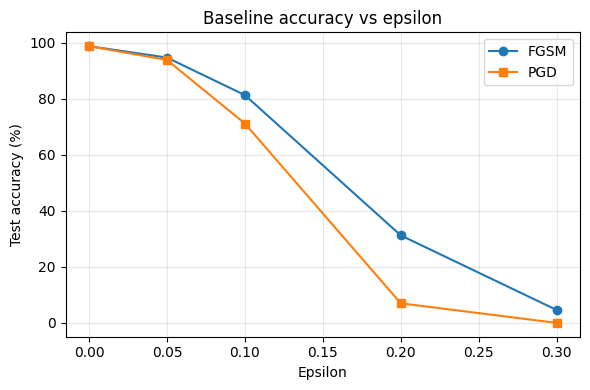

MODEL CLEAN FGSM(0.20) PGD(0.20)
----------------------------------------------------
Baseline 98.9 % 31.3 % 7.0 %
Adversarially trained 99.0 % 88.8 % 70.7 %
----------------------------------------------------
Clean accuracy change : +0.2 %
FGSM robustness gain : +57.6 % PGD gain : +63.7 %
Plot saved : accuracy_vs_epsilon.png


In [7]:
plt.figure(figsize=(6, 4))
plt.plot(EPS_LIST, fgsm_accs, marker="o", label="FGSM")
plt.plot(EPS_LIST, pgd_accs, marker="s", label="PGD")
plt.xlabel("Epsilon"); plt.ylabel("Test accuracy (%)"); plt.title("Baseline accuracy vs epsilon")
plt.legend(); plt.grid(alpha=0.3); plt.tight_layout()
plt.savefig("accuracy_vs_epsilon.png", dpi=150)
plt.show()

print("MODEL CLEAN FGSM(0.20) PGD(0.20)")
print("-" * 52)
print(f"Baseline {base[0]:.1f} % {base[1]:.1f} % {base[2]:.1f} %")
print(f"Adversarially trained {rob[0]:.1f} % {rob[1]:.1f} % {rob[2]:.1f} %")
print("-" * 52)
print(f"Clean accuracy change : {rob[0] - base[0]:+.1f} %")
print(f"FGSM robustness gain : {rob[1] - base[1]:+.1f} % PGD gain : {rob[2] - base[2]:+.1f} %")
print("Plot saved : accuracy_vs_epsilon.png")